# Лабораторна робота №5. Обчислення вейвлет коефіцієнтів. Пряме і обернене вейвлет перетворення

Варіант 23: вейвлет Добеші 12-го порядку (db12), рівень розкладу 4, поріг rigrsure, м'який тип порогу, масштабування типу 2, сигнал `Lab_3_23.mat`.

## Вихідні дані

Імпортуємо бібліотеки (у Colab спочатку встановлюється PyWavelets), задаємо параметри варіанту і завантажуємо сигнал зі змінної `signal` файлу `Lab_3_23.mat`. У файлі також є частота дискретизації `Fd` = 1000 Гц, тому 1000 відліків тривають 1 с.

In [1]:
import importlib.util
import subprocess
import sys
import urllib.request
from pathlib import Path

# Colab has NumPy, SciPy and matplotlib, but not PyWavelets, so install it there first.
if "google.colab" in sys.modules and importlib.util.find_spec("pywt") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "PyWavelets"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pywt
from scipy.io import loadmat

variant_number = 23
wavelet_name = "db12"  # Daubechies wavelet of order 12
decomposition_level = 4
threshold_rule = "rigrsure"  # Stein's unbiased risk estimate
threshold_mode = "soft"
extension_mode = "symmetric"  # how the signal is extended past its ends before filtering

# The signal file of the variant. In Colab it is downloaded from the repository if it is missing.
data_file = Path("Lab_3_23.mat")
data_url = ("https://raw.githubusercontent.com/serafindanyil/digital-signal-processing/"
            "lab-5/lab-5/Lab_3_23.mat")
if not data_file.exists():
    urllib.request.urlretrieve(data_url, data_file)

mat_data = loadmat(data_file)
signal_values = mat_data["signal"].astype(float).ravel()
sampling_frequency = float(mat_data["Fd"].squeeze())
sampling_period = 1 / sampling_frequency
sample_count = len(signal_values)
sample_times = np.arange(sample_count) * sampling_period

print(f"Variant {variant_number}: wavelet {wavelet_name}, level {decomposition_level},"
      f" rule {threshold_rule}, {threshold_mode} thresholding, scaling type 2")
print(f"Samples N = {sample_count}, Fd = {sampling_frequency:.0f} Hz, Ta = {sampling_period} s,"
      f" duration {sample_count * sampling_period:.1f} s")
print(f"Signal: mean {signal_values.mean():.6f}, std {signal_values.std():.6f},"
      f" min {signal_values.min():.6f}, max {signal_values.max():.6f}")

Variant 23: wavelet db12, level 4, rule rigrsure, soft thresholding, scaling type 2
Samples N = 1000, Fd = 1000 Hz, Ta = 0.001 s, duration 1.0 s
Signal: mean 0.026576, std 0.758014, min -1.496358, max 1.460490


## Крок 1. Вейвлет-декомпозиція (алгоритм Маллата)

Фільтри Lo_D, Hi_D, Lo_R, Hi_R вейвлета db12 мають по 24 коефіцієнти. Функція `pywt.wavedec` чотири рази фільтрує апроксимацію і проріджує результат на два (↓2), тож отримуємо вектор [cA₄, cD₄, cD₃, cD₂, cD₁]. Перевірка: `pywt.waverec` з незміненими коефіцієнтами відновлює сигнал, тобто S = A₄ + D₄ + D₃ + D₂ + D₁.

In [2]:
wavelet = pywt.Wavelet(wavelet_name)
# The four filters of the guide: low and high pass for decomposition (Lo_D, Hi_D)
# and for reconstruction (Lo_R, Hi_R).
print(f"Filter lengths: Lo_D {len(wavelet.dec_lo)}, Hi_D {len(wavelet.dec_hi)},"
      f" Lo_R {len(wavelet.rec_lo)}, Hi_R {len(wavelet.rec_hi)}")
print(f"Sum of Lo_D = {np.sum(wavelet.dec_lo):.6f} (square root of 2 = {np.sqrt(2):.6f}),"
      f" sum of squares = {np.sum(np.square(wavelet.dec_lo)):.6f}")
maximum_level = pywt.dwt_max_level(sample_count, wavelet.dec_len)
print(f"Maximum useful level for {sample_count} samples: {maximum_level}")

# wavedec repeats the step "filter, then keep every second sample" on the approximation.
# It returns the list [cA4, cD4, cD3, cD2, cD1], the same order as the vector C in the guide.
coefficients = pywt.wavedec(signal_values, wavelet, mode=extension_mode, level=decomposition_level)
approximation_coefficients = coefficients[0]
detail_coefficients = {level_index: coefficients[-level_index]
                       for level_index in range(1, decomposition_level + 1)}
print(f"cA{decomposition_level}: {len(approximation_coefficients)} coefficients")
for level_index in range(decomposition_level, 0, -1):
    print(f"cD{level_index}: {len(detail_coefficients[level_index])} coefficients")

# Reconstruction from the untouched coefficients must give back the original signal.
restored_signal = pywt.waverec(coefficients, wavelet, mode=extension_mode)[:sample_count]
reconstruction_error = np.max(np.abs(restored_signal - signal_values))
print(f"max |waverec(wavedec(s)) - s| = {reconstruction_error:.1e}")

Filter lengths: Lo_D 24, Hi_D 24, Lo_R 24, Hi_R 24
Sum of Lo_D = 1.414214 (square root of 2 = 1.414214), sum of squares = 1.000000
Maximum useful level for 1000 samples: 5
cA4: 84 coefficients
cD4: 84 coefficients
cD3: 145 coefficients
cD2: 267 coefficients
cD1: 511 coefficients
max |waverec(wavedec(s)) - s| = 1.3e-15


## Крок 2. Оцінка рівня шуму (масштабування типу 2)

Для кожного рівня окремо оцінюємо стандартне відхилення шуму за деталізуючими коефіцієнтами: σᵢ = median(|cDᵢ|) / 0,6745.

In [3]:
# The noise estimate is the median of the absolute detail coefficients divided by 0.6745.
# For white noise this median-based value equals the standard deviation and is not
# spoiled by the few large coefficients that belong to the useful signal.
noise_levels = {}
for level_index in range(1, decomposition_level + 1):
    noise_levels[level_index] = np.median(np.abs(detail_coefficients[level_index])) / 0.6745
    print(f"cD{level_index}: noise estimate sigma = {noise_levels[level_index]:.6f}")

cD1: noise estimate sigma = 0.287826
cD2: noise estimate sigma = 0.312228
cD3: noise estimate sigma = 0.266881
cD4: noise estimate sigma = 0.219739


## Крок 3. Поріг rigrsure

Правило rigrsure шукає поріг, за якого незміщена оцінка ризику Штейна мінімальна. Воно розраховане на шум з одиничною дисперсією, тому спочатку ділимо cDᵢ на σᵢ, знаходимо поріг, а потім множимо його на σᵢ: thrᵢ = rigrsure(cDᵢ/σᵢ)·σᵢ. Перевірка: прямий перебір ризику SURE(t) = n − 2·#{|x| ≤ t} + Σmin(x², t²) для всіх кандидатів дає той самий поріг.

In [4]:
# The rule assumes noise with unit variance, so the details are divided by sigma first,
# and the threshold found is multiplied by sigma back (scaling type 2 of the guide).
normalized_thresholds = {}
thresholds = {}
brute_force_difference = 0.0
for level_index in range(1, decomposition_level + 1):
    normalized_details = detail_coefficients[level_index] / noise_levels[level_index]
    coefficient_count = len(normalized_details)
    # Candidate thresholds are the absolute coefficients themselves, sorted from small to large.
    sorted_squares = np.sort(np.abs(normalized_details)) ** 2
    candidate_numbers = np.arange(1, coefficient_count + 1)
    # Risk of each candidate: count - 2 * (coefficients below it) + (sum of squares below it)
    # + (coefficients above it) * candidate^2, divided by the count.
    risks = (coefficient_count - 2 * candidate_numbers + np.cumsum(sorted_squares)
             + (coefficient_count - candidate_numbers) * sorted_squares) / coefficient_count
    best_candidate = np.argmin(risks)
    normalized_thresholds[level_index] = np.sqrt(sorted_squares[best_candidate])
    thresholds[level_index] = normalized_thresholds[level_index] * noise_levels[level_index]

    # Check: compute the Stein risk directly for every candidate and take the smallest one.
    candidates = np.sort(np.abs(normalized_details))
    direct_risks = [coefficient_count - 2 * np.sum(np.abs(normalized_details) <= candidate)
                    + np.sum(np.minimum(normalized_details ** 2, candidate ** 2))
                    for candidate in candidates]
    direct_threshold = candidates[np.argmin(direct_risks)]
    brute_force_difference = max(brute_force_difference,
                                 abs(direct_threshold - normalized_thresholds[level_index]))
    print(f"cD{level_index}: rigrsure(cD/sigma) = {normalized_thresholds[level_index]:.6f},"
          f" threshold = {thresholds[level_index]:.6f}")
print(f"max |sorted formula - direct risk minimum| = {brute_force_difference:.1e}")

cD1: rigrsure(cD/sigma) = 2.893135, threshold = 0.832718
cD2: rigrsure(cD/sigma) = 2.495599, threshold = 0.779195
cD3: rigrsure(cD/sigma) = 1.491916, threshold = 0.398164
cD4: rigrsure(cD/sigma) = 0.733618, threshold = 0.161205
max |sorted formula - direct risk minimum| = 0.0e+00


## Крок 4. М'яке порогування і реконструкція

Коефіцієнти, менші за поріг за модулем, обнуляємо, решту зменшуємо за модулем на величину порогу. Результат порівнюємо з `pywt.threshold(..., mode="soft")`. Апроксимацію cA₄ не змінюємо, а очищений сигнал відновлюємо функцією `pywt.waverec`.

In [5]:
# Soft thresholding (section 1.2 of the guide): coefficients smaller than the threshold
# become zero, the others move closer to zero by the threshold value.
# The approximation cA4 holds the smooth part of the signal and is kept as it is.
thresholded_details = {}
zeroed_counts = {}
soft_difference = 0.0
for level_index in range(1, decomposition_level + 1):
    details = detail_coefficients[level_index]
    thresholded_details[level_index] = np.sign(details) * np.maximum(np.abs(details) - thresholds[level_index], 0)
    library_details = pywt.threshold(details, thresholds[level_index], mode=threshold_mode)
    soft_difference = max(soft_difference, np.max(np.abs(thresholded_details[level_index] - library_details)))
    zeroed_counts[level_index] = int(np.sum(thresholded_details[level_index] == 0))
print(f"max |soft rule by hand - pywt.threshold| = {soft_difference:.1e}")

# Reconstruction from cA4 and the changed details, in the order [cA4, cD4, cD3, cD2, cD1].
denoised_coefficients = [approximation_coefficients] + [thresholded_details[level_index]
                                                        for level_index in range(decomposition_level, 0, -1)]
denoised_signal = pywt.waverec(denoised_coefficients, wavelet, mode=extension_mode)[:sample_count]
removed_component = signal_values - denoised_signal
print(f"Denoised signal: mean {denoised_signal.mean():.6f}, std {denoised_signal.std():.6f},"
      f" min {denoised_signal.min():.6f}, max {denoised_signal.max():.6f}")
print(f"Removed component: RMS {np.sqrt(np.mean(removed_component ** 2)):.6f},"
      f" max |value| {np.max(np.abs(removed_component)):.6f}")

max |soft rule by hand - pywt.threshold| = 1.1e-16
Denoised signal: mean 0.026336, std 0.710087, min -1.149904, max 1.173257
Removed component: RMS 0.257209, max |value| 0.595790


## Рисунок 1. Сигнал до і після очищення

Зверху зашумлений сигнал, посередині очищений, знизу видалена складова (різниця між ними).

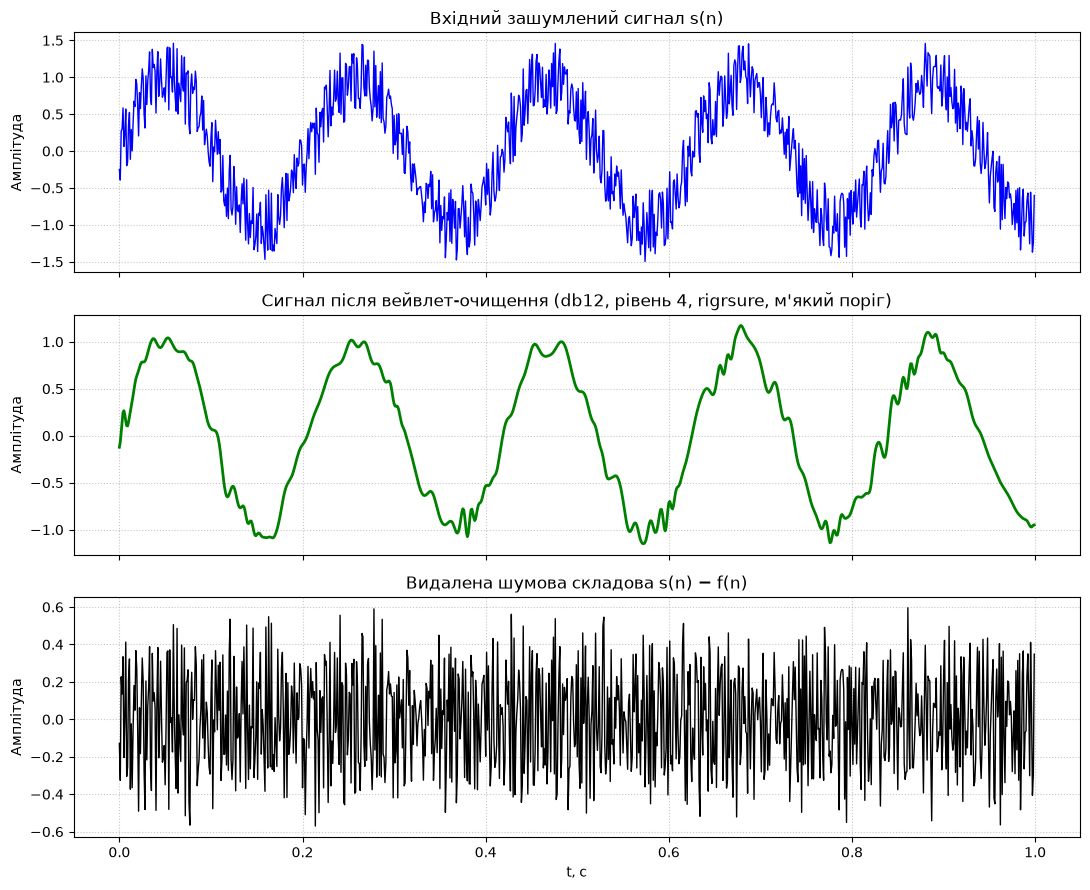

In [6]:
Path("figures").mkdir(exist_ok=True)
figure, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
axes[0].plot(sample_times, signal_values, color="blue", linewidth=1)
axes[0].set_title("Вхідний зашумлений сигнал s(n)")
axes[1].plot(sample_times, denoised_signal, color="green", linewidth=2)
axes[1].set_title(f"Сигнал після вейвлет-очищення ({wavelet_name}, рівень {decomposition_level},"
                  f" {threshold_rule}, м'який поріг)")
axes[2].plot(sample_times, removed_component, color="black", linewidth=1)
axes[2].set_title("Видалена шумова складова s(n) − f(n)")
axes[2].set_xlabel("t, с")
for axis in axes:
    axis.set_ylabel("Амплітуда")
    axis.grid(linestyle=":", alpha=0.7)
plt.tight_layout()
plt.savefig("figures/signal_denoising.png", dpi=180)
plt.show()

## Рисунок 2. Деталізуючі коефіцієнти до і після порогування

Ліворуч коефіцієнти cD₄…cD₁ з порогами ±thrᵢ (червоні штрихові лінії), праворуч ті самі коефіцієнти після м'якого порогування.

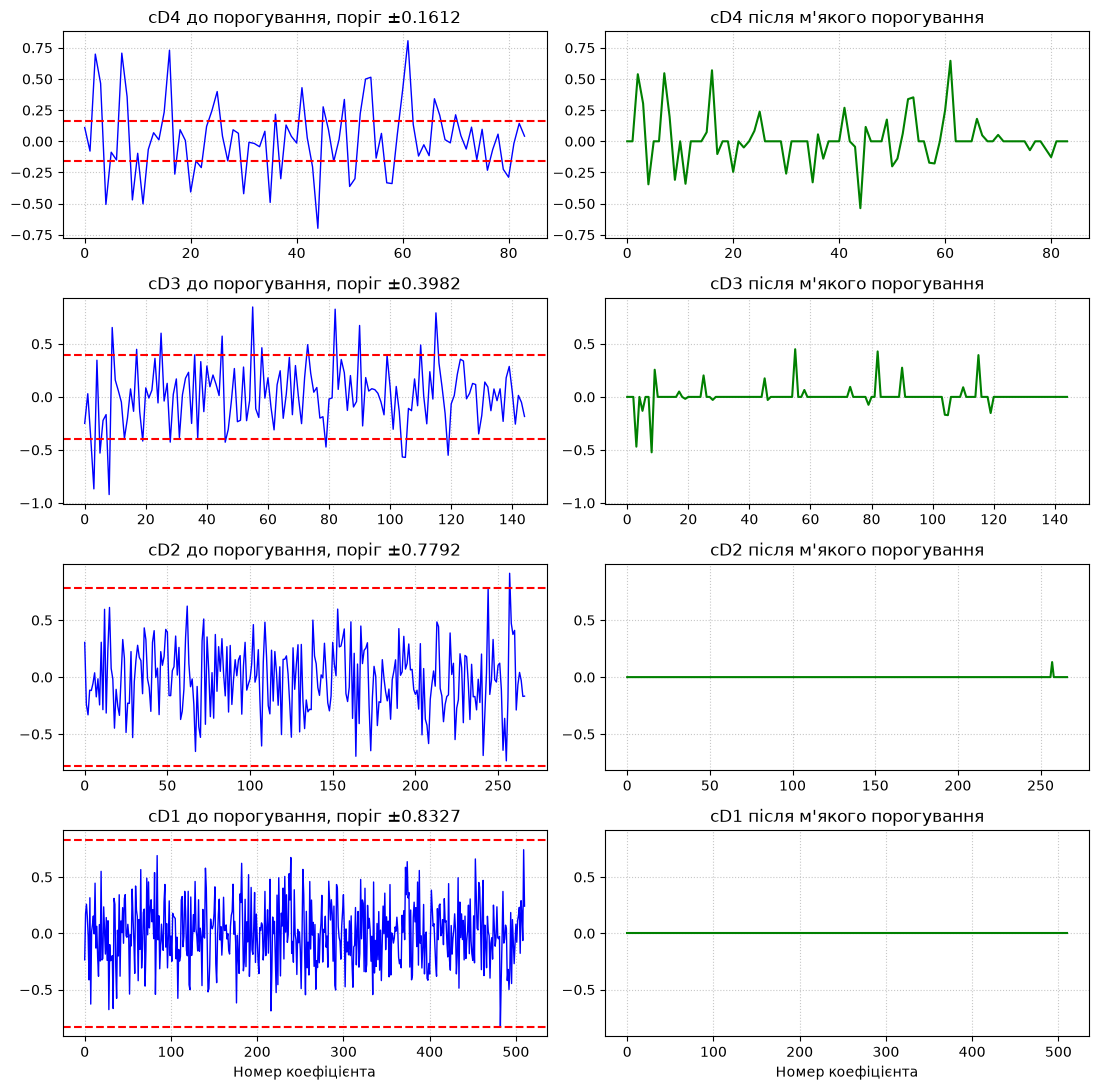

In [7]:
figure, axes = plt.subplots(decomposition_level, 2, figsize=(11, 11))
for row_index, level_index in enumerate(range(decomposition_level, 0, -1)):
    before_axis, after_axis = axes[row_index]
    before_axis.plot(detail_coefficients[level_index], color="blue", linewidth=1)
    before_axis.axhline(thresholds[level_index], color="red", linestyle="--", linewidth=1.5)
    before_axis.axhline(-thresholds[level_index], color="red", linestyle="--", linewidth=1.5)
    before_axis.set_title(f"cD{level_index} до порогування, поріг ±{thresholds[level_index]:.4f}")
    after_axis.plot(thresholded_details[level_index], color="green", linewidth=1.5)
    after_axis.set_title(f"cD{level_index} після м'якого порогування")
    after_axis.set_ylim(before_axis.get_ylim())  # same scale, so the shrinking is visible
    for axis in (before_axis, after_axis):
        axis.grid(linestyle=":", alpha=0.7)
axes[-1, 0].set_xlabel("Номер коефіцієнта")
axes[-1, 1].set_xlabel("Номер коефіцієнта")
plt.tight_layout()
plt.savefig("figures/detail_coefficients.png", dpi=180)
plt.show()

## Підсумок

Таблиця порогів за рівнями, кількість обнулених коефіцієнтів, статистика сигналів і найбільша розбіжність перевірок.

In [8]:
print(f"Variant {variant_number}: {wavelet_name}, level {decomposition_level}, {threshold_rule},"
      f" {threshold_mode}, scaling type 2, {data_file.name}")
print(f"{'level':>6} {'count':>6} {'sigma':>9} {'rigrsure':>9} {'threshold':>10} {'zeroed':>14}")
for level_index in range(1, decomposition_level + 1):
    coefficient_count = len(detail_coefficients[level_index])
    print(f"{'cD' + str(level_index):>6} {coefficient_count:>6} {noise_levels[level_index]:9.6f}"
          f" {normalized_thresholds[level_index]:9.6f} {thresholds[level_index]:10.6f}"
          f" {zeroed_counts[level_index]:>5} ({100 * zeroed_counts[level_index] / coefficient_count:5.1f} %)")
print(f"std: noisy {signal_values.std():.6f}, denoised {denoised_signal.std():.6f},"
      f" removed RMS {np.sqrt(np.mean(removed_component ** 2)):.6f}")
largest_difference = max(reconstruction_error, brute_force_difference, soft_difference)
print(f"Largest check difference (reconstruction, rigrsure, soft rule): {largest_difference:.1e}")

Variant 23: db12, level 4, rigrsure, soft, scaling type 2, Lab_3_23.mat
 level  count     sigma  rigrsure  threshold         zeroed
   cD1    511  0.287826  2.893135   0.832718   511 (100.0 %)
   cD2    267  0.312228  2.495599   0.779195   266 ( 99.6 %)
   cD3    145  0.266881  1.491916   0.398164   124 ( 85.5 %)
   cD4     84  0.219739  0.733618   0.161205    46 ( 54.8 %)
std: noisy 0.758014, denoised 0.710087, removed RMS 0.257209
Largest check difference (reconstruction, rigrsure, soft rule): 1.3e-15
